In [321]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_mvcp import *
from utils import *
from utils_spec import *
import os
from tqdm import tqdm
import json
from datetime import date

In [322]:
# Get the current date
todays_date = date.today()
year = str(todays_date.year)
if todays_date.month < 10:
    month = '0'+str(todays_date.month)
else:
    month = str(todays_date.month)

if todays_date.day < 10:
    day = '0'+str(todays_date.day)
else:
    day = str(todays_date.day)

current_date = year+month+day
directory_name = 'results/'+current_date
if not os.path.isdir(directory_name):
    os.mkdir(directory_name)
    
directory_name

'results/20251022'

In [323]:
remove_slopp = pd.read_excel('RochmanSpectra_ToRemove.xlsx', sheet_name="SLOPPe Remove")

mIRageLibraySpectra_Removed = pd.read_csv('../gloves_contamination/mIRageLibraySpectra_Removed.csv')
mIRageLibraySpectra_Removed.iloc[-1,2] = 'PE_15'

dict_slopp_reb = {'PE':'Polyethylene', 
                  'PP':'Polypropylene', 
                  'PSL':'Polystyrene'}

with open('processed_data/passive_data_raman_saturation.json', 'r') as f:
    saturated_wn_dict = json.load(f)

    
ids_sat = list(saturated_wn_dict.keys())

slopp_df = pd.read_csv('processed_data/slopp_data_raman_final_specy.csv')
del slopp_df['Unnamed: 0']
slopp_df.columns = list(np.float64(slopp_df.columns[:-4])) + list(slopp_df.columns[-4:])

slopp_df = slopp_df.query('polymer != "Cotton" and polymer !="Dyed Cellulose"').reset_index(drop=True)
slopp_df.loc[slopp_df['polymer'] == "Polyester",'polymer'] = "Polyethylene Terephthalate"
slopp_df = slopp_df.loc[[x not in np.array(remove_slopp['Example']) for x in slopp_df['id']], :].reset_index(drop=True)

rebecca_raman_df = pd.read_csv('processed_data/rebecca_data_raman_final_specy.csv')
del rebecca_raman_df['Unnamed: 0']
rebecca_raman_df.columns = list(np.float64(rebecca_raman_df.columns[:-4])) + list(rebecca_raman_df.columns[-4:])

rebecca_raman_df = rebecca_raman_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "Raman"')['ID']) for x in rebecca_raman_df['id']])[0],
                             axis=0).reset_index(drop=True)

rebecca_raman_df = rebecca_raman_df.query('polymer in @dict_slopp_reb').reset_index(drop=True)
rebecca_raman_df['polymer'] = [dict_slopp_reb[x] for x in rebecca_raman_df['polymer']]

passive_data_raman = pd.read_csv('processed_data/passive_data_raman_specy.csv')
del passive_data_raman['Unnamed: 0']
del passive_data_raman['wn_saturated']
del passive_data_raman['id_file']
ids_no_signal = np.array(passive_data_raman.query('no_signal>0')['id'])
del passive_data_raman['no_signal']
passive_data_raman.columns = list(np.float64(passive_data_raman.columns[:-3])) + list(passive_data_raman.columns[-3:])
passive_data_raman['polymer'] = ''
passive_data_raman['label'] = ''

min_raman_1 = 600
max_raman_1 = 910

min_raman_2 = 1040
max_raman_2 = 2310

min_raman_3 = 2500
max_raman_3 = 3500

#min_raman_1 = 600
#max_raman_1 = 1000

#min_raman_2 = 1600
#max_raman_2 = 3500

#min_raman_3 = 2500
#max_raman_3 = 3500

idx_1 = list(
    np.logical_or( 
        np.logical_or(
            np.logical_and(
                wn_raman > min_raman_1,
                wn_raman < max_raman_1),
            np.logical_and(
                wn_raman > min_raman_2,
                wn_raman < max_raman_2)
            ),   
        np.logical_and(
            wn_raman > min_raman_3,
            wn_raman < max_raman_3)
    )
    ) + [True]*4


wn_raman = np.float64(slopp_df.columns[:-4])

min_raman_1 = 600
max_raman_1 = 1850

min_raman_2 = 2750
max_raman_2 = 3500

idx_1 = list(np.logical_or(
    np.logical_and(
        wn_raman > min_raman_1,
        wn_raman < max_raman_1),
    np.logical_and(
        wn_raman > min_raman_2,
        wn_raman < max_raman_2))) + [True]*4


idx_2 = idx_1[:-4] + [False]*4

slopp_df = slopp_df.loc[:,idx_1]
rebecca_raman_df = rebecca_raman_df.loc[:,idx_1]
passive_data_raman = passive_data_raman.loc[:,idx_1+[True]]
#passive_data_raman = passive_data_raman.query('id != "DC_passive_June2024_I7_20240717_90"').reset_index(drop=True)

slopp_df.iloc[:,:-4] = (slopp_df.iloc[:,:-4] - slopp_df.iloc[:,:-4].mean(1)[:,None]) / slopp_df.iloc[:,:-4].std(1)[:,None]
rebecca_raman_df.iloc[:,:-4] = (rebecca_raman_df.iloc[:,:-4] - rebecca_raman_df.iloc[:,:-4].mean(1)[:,None]) / rebecca_raman_df.iloc[:,:-4].std(1)[:,None]
passive_data_raman.iloc[:,:-5] = (passive_data_raman.iloc[:,:-5] - passive_data_raman.iloc[:,:-5].mean(1)[:,None]) / passive_data_raman.iloc[:,:-5].std(1)[:,None]

ids_no_signal = np.unique(
    np.concatenate([ids_no_signal,
    np.array(passive_data_raman.loc[passive_data_raman.iloc[:,:-5].T.std()<.01,'id'])]))

idx_raman_nan = np.unique(np.where(np.isnan(passive_data_raman.iloc[:,:-5]))[0])


In [324]:
remove_flopp = pd.read_excel('RochmanSpectra_ToRemove.xlsx', sheet_name="FLOPPe Remove")

flopp_df = pd.read_csv('processed_data/flopp_data_ir_final.csv')
del flopp_df['Unnamed: 0']
flopp_df.columns = list(np.float64(flopp_df.columns[:-4])) + list(flopp_df.columns[-4:])
flopp_df = flopp_df.query('polymer != "Cotton"').reset_index(drop=True)
flopp_df.columns = list(np.float64(flopp_df.columns[:-4])) + list(flopp_df.columns[-4:])
flopp_df = flopp_df.loc[[x not in np.array(remove_flopp['Example']) for x in flopp_df['id']], :].reset_index(drop=True)

rebecca_ir_df = pd.read_csv('processed_data/rebecca_data_ir_final.csv')
del rebecca_ir_df['Unnamed: 0']
rebecca_ir_df.columns = list(np.float64(rebecca_ir_df.columns[:-4])) + list(rebecca_ir_df.columns[-4:])

rebecca_ir_df = rebecca_ir_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "PTIR"')['ID']) for x in rebecca_ir_df['id']])[0],
                             axis=0).reset_index(drop=True)

rebecca_ir_df = rebecca_ir_df.query('polymer in @dict_slopp_reb').reset_index(drop=True)
rebecca_ir_df['polymer'] = [dict_slopp_reb[x] for x in rebecca_ir_df['polymer']]


passive_data_ir = pd.read_csv('processed_data/passive_data_ir.csv')
del passive_data_ir['Unnamed: 0']
background_ids = np.array(passive_data_ir.query('background == "background"')['id'])
passive_data_ir.columns = list(np.float64(passive_data_ir.columns[:-4])) + list(passive_data_ir.columns[-4:])
passive_data_ir['polymer'] = ''
passive_data_ir['label'] = ''

#passive_data_ir = passive_data_ir.query('id != "DC_passive_June2024_I7_20240717_90"').reset_index(drop=True)

flopp_df.iloc[:,:-4] = (flopp_df.iloc[:,:-4] - flopp_df.iloc[:,:-4].mean(1)[:,None]) / flopp_df.iloc[:,:-4].std(1)[:,None]
rebecca_ir_df.iloc[:,:-4] = (rebecca_ir_df.iloc[:,:-4] - rebecca_ir_df.iloc[:,:-4].mean(1)[:,None]) / rebecca_ir_df.iloc[:,:-4].std(1)[:,None]
passive_data_ir.iloc[:,:-6] = (passive_data_ir.iloc[:,:-6] - passive_data_ir.iloc[:,:-6].mean(1)[:,None]) / passive_data_ir.iloc[:,:-6].std(1)[:,None]

In [325]:
FINAL_PTIR_LikelyMPs = pd.read_excel('evaluation_data/FINAL_PTIR_LikelyMPs.xlsx', header=None).to_numpy().flatten()
FINAL_PTIR_Noise = pd.read_excel('evaluation_data/FINAL_PTIR_Noise.xlsx', header=None).to_numpy().flatten()
FINAL_PTIR_NonMPs = pd.read_excel('evaluation_data/FINAL_PTIR_NonMPs.xlsx', header=None).to_numpy().flatten()

In [326]:
Passive_RamanOnly_Manual_LikelyMPs = pd.read_excel('evaluation_data/Passive_RamanOnly_Manual_LikelyMPs.xlsx', header=None).to_numpy().flatten()

In [327]:
#particle_info = pd.read_csv('processed_data/passive_data_raman_specy_particle_info.csv')
#particle_info = particle_info.loc[:,['id','size','area','perimeter','circularity','distance']]
#particle_info.to_csv('processed_data/particle_info_passive_data.csv')

In [328]:
passive_data_ir_paired = passive_data_ir.query('id not in @ids_sat and id not in @background_ids and id not in @ids_no_signal').reset_index(drop=True)
passive_data_ir_unpaired_ram = passive_data_ir.query('(id not in @ids_sat and id not in @ids_no_signal) and id in @background_ids').reset_index(drop=True)
passive_data_ir_unpaired_ir = passive_data_ir.query('(id in @ids_sat or id in @ids_no_signal) and id not in @background_ids').reset_index(drop=True)
passive_data_ir_nopair = passive_data_ir.query('(id in @ids_sat or id in @ids_no_signal) and id in @background_ids').reset_index(drop=True)

passive_data_raman_paired = passive_data_raman.query('id not in @idx_raman_nan and (id not in @ids_sat and id not in @ids_no_signal) and id not in @background_ids').reset_index(drop=True)
passive_data_raman_unpaired_ram = passive_data_raman.query('id not in @idx_raman_nan and (id not in @ids_sat and id not in @ids_no_signal) and id in @background_ids').reset_index(drop=True)
passive_data_raman_unpaired_ir = passive_data_raman.query('(id not in @idx_raman_nan or id in @ids_sat or id in @ids_no_signal) and id not in @background_ids').reset_index(drop=True)
passive_data_raman_nopair = passive_data_raman.query('(id not in @idx_raman_nan or id in @ids_sat or id in @ids_no_signal) and id in @background_ids').reset_index(drop=True)


In [329]:
(np.sum([x in FINAL_PTIR_LikelyMPs for x in passive_data_ir_paired['id']]),
np.sum([x in FINAL_PTIR_Noise for x in passive_data_ir_paired['id']]),
np.sum([x in FINAL_PTIR_NonMPs for x in passive_data_ir_paired['id']]))

(2, 0, 2)

In [330]:
(np.sum([x in FINAL_PTIR_LikelyMPs for x in passive_data_ir_unpaired_ir['id']]),
np.sum([x in FINAL_PTIR_Noise for x in passive_data_ir_unpaired_ir['id']]),
np.sum([x in FINAL_PTIR_NonMPs for x in passive_data_ir_unpaired_ir['id']]))

(467, 205, 266)

In [331]:
print('unpaired Raman spectra: ', passive_data_ir_unpaired_ram.shape[0])
print('unpaired IR spectra: ', passive_data_ir_unpaired_ir.shape[0])
print('no pair spectra: ', passive_data_ir_nopair.shape[0])
print('paired spectra: ', passive_data_ir_paired.shape[0])

unpaired Raman spectra:  1824
unpaired IR spectra:  2096
no pair spectra:  193
paired spectra:  4073


In [332]:
print('raman spectra with no signal: ', ids_no_signal.shape[0]),
print('raman spectra with saturation: ', len(ids_sat))
print('ir spectra with background: ', len([x for x in background_ids if x not in list(ids_no_signal) + ids_sat]))
print('rest spectra: ', passive_data_raman_paired.shape[0])

raman spectra with no signal:  505
raman spectra with saturation:  1785
ir spectra with background:  1824
rest spectra:  4073


In [333]:
slopp_df.groupby('polymer').count().iloc[:,-1:].merge(flopp_df.groupby('polymer').count().iloc[:,-1:], 
                                                      left_index=True,
                                                      right_index=True, how='outer')

,id_x,id_y
polymer,,
Acrylic,8.0,5.0
Acrylonitrile Butadiene Styrene,10.0,14.0
Cellulose Acetate,3.0,2.0
Ethylene Acrylic Acid,NaN,1.0
Polyamide,13.0,18.0
Polybutylene Terephthalate,1.0,NaN
Polycarbonate,8.0,8.0
Polyethylene,43.0,65.0
Polyethylene Adipate,NaN,1.0


In [334]:
flopp_slopp_labels = np.array(slopp_df.groupby('polymer').count().iloc[:,-1:].merge(flopp_df.groupby('polymer').count().iloc[:,-1:], 
                                                      left_index=True,
                                                      right_index=True, how='inner').index)

flopp_df = flopp_df.query('polymer in @flopp_slopp_labels').reset_index(drop=True)
slopp_df = slopp_df.query('polymer in @flopp_slopp_labels').reset_index(drop=True)


In [335]:
slopp_df.groupby('polymer').count().iloc[:,-1:].merge(flopp_df.groupby('polymer').count().iloc[:,-1:], 
                                                      left_index=True,
                                                      right_index=True, how='outer')

,id_x,id_y
polymer,,
Acrylic,8,5
Acrylonitrile Butadiene Styrene,10,14
Cellulose Acetate,3,2
Polyamide,13,18
Polycarbonate,8,8
Polyethylene,43,65
Polyethylene Terephthalate,32,47
Polyethylene Vinyl Acetate,2,13
Polymethyl Methacrylate,3,2


In [336]:
idx_both_rebecca = np.array(rebecca_ir_df.loc[[x in np.array(rebecca_raman_df['id']) for x in rebecca_ir_df['id']],'id'])# 
rebecca_ir_df = rebecca_ir_df.query('id in @idx_both_rebecca').reset_index(drop=True)
rebecca_raman_df = rebecca_raman_df.query('id in @idx_both_rebecca').reset_index(drop=True)


# Paired

In [284]:
(reference_library_raman, 
 calibration_set_raman, 
 test_set_raman, 
 label_table_raman) = gen_data_sets(slopp_df,
                                    rebecca_raman_df,
                                    passive_data_raman_paired)

(X_train_raman, X_cal_raman, X_test_raman, 
 y_train_raman, y_cal_raman, y_test_raman, 
 label_train_raman, label_cal_raman, label_test_raman, 
 n_test_raman, wl_list_raman) = process_data(reference_library_raman,
                                             calibration_set_raman,
                                             test_set_raman)




In [285]:
(reference_library_ir, 
 calibration_set_ir, 
 test_set_ir, 
 label_table_ir) = gen_data_sets_ir(flopp_df, 
                              rebecca_ir_df, 
                              passive_data_ir_paired)

(X_train_ir, X_cal_ir, X_test_ir, 
 y_train_ir, y_cal_ir, y_test_ir, 
 label_train_ir, label_cal_ir, label_test_ir, 
 n_test_ir, wl_list_ir) = process_data_ir(reference_library_ir,
                                 calibration_set_ir,
                                 test_set_ir)

In [286]:
pred_slopp_df = corr_matching(np.array(slopp_df.iloc[:,:-4]), 
                              slopp_df['polymer'], 
                              np.array(calibration_set_raman.iloc[:,3:]), r_min=0)

pred_flopp_df = corr_matching(np.array(flopp_df.iloc[:,:-4]), 
                              flopp_df['polymer'], 
                              np.array(calibration_set_ir.iloc[:,3:]), r_min=0)

(np.mean(np.array(pred_slopp_df[0]) == np.array(calibration_set_raman['polymer'])),
 np.mean(np.array(pred_flopp_df[0]) == np.array(calibration_set_ir['polymer'])))

(0.5219512195121951, 0.6292682926829268)

In [287]:
#pred_slopp_df = corr_matching(np.array(slopp_df.iloc[:,:-4]), 
#                              slopp_df['polymer'], 
#                              np.array(test_set_raman.iloc[:,3:]), r_min=0)

#pred_flopp_df = corr_matching(np.array(flopp_df.iloc[:,:-4]), 
#                              flopp_df['polymer'], 
#                              np.array(test_set_ir.iloc[:,3:]), r_min=0)

In [288]:
#pred_flopp_df = matching(flopp_df, passive_data_ir.iloc[:,:-2], limits=((980,1800),(2720, 2970)), lib_name='ref', data_name='final')
#pred_slopp_df = matching_r(slopp_df, test_set_raman.iloc[:,list(range(3,test_set_raman.shape[1]))+[0]], limits=(600,3500), lib_name='ref', data_name='final')


In [289]:
alpha = 0.1

In [290]:
from sklearn.linear_model import LogisticRegression

In [291]:
def smx_log(X_train, X_test, labels_train, C=0.01):
    
    clf = LogisticRegression(random_state=0, C=C).fit(X_train, labels_train)
    smx = clf.predict_proba(X_test)
    label_pred = clf.predict(X_test)
    
    return smx

In [292]:
np.mean(np.argmax(smx_cal, 1) == label_cal_ir)

0.6292682926829268

In [110]:
# Calculate HQI for calibration set
smx_cal = smx_log(X_train_ir, X_cal_ir, label_train_ir)

# Calculate HQI for test set
smx_test = smx_log(X_train_ir, X_test_ir, label_train_ir)


#smx_test_all = smx_nn_all(
#        X_train_ir, 
#        X_test_ir, 
#        label_train_ir
#)

#pred_flopp_df = [
#    np.array(label_table_ir.iloc[np.argmax(smx_test, 1),1]),
#    np.max(smx_test, 1),
#    np.array(reference_library_ir.iloc[np.argmax(smx_test_all, 0),0])
#]

# Set confidence level 1 - alpha
n = smx_cal.shape[0]
#alpha = 0.1
#for alpha in [alpha]:
prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal_ir, n, alpha, cond=0)

prediction_sets_n = [list(label_table_ir.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())
print('HQI cutt off:', 1-qhat)

Sets with zero labels: 0
Sets with one label: 2
Sets with >1 labels: 4071
Mean set size: 7.591946967836975
Std set size: 2.115369722933887
HQI cutt off: 0.024169194598291588


In [33]:
# Calculate HQI for calibration set
smx_cal = smx_nn(X_train_ir, X_cal_ir, label_train_ir)

# Calculate HQI for test set
smx_test = smx_nn(X_train_ir, X_test_ir, label_train_ir)


#smx_test_all = smx_nn_all(
#        X_train_ir, 
#        X_test_ir, 
#        label_train_ir
#)

#pred_flopp_df = [
#    np.array(label_table_ir.iloc[np.argmax(smx_test, 1),1]),
#    np.max(smx_test, 1),
#    np.array(reference_library_ir.iloc[np.argmax(smx_test_all, 0),0])
#]

# Set confidence level 1 - alpha
n = smx_cal.shape[0]
#alpha = 0.1
#for alpha in [alpha]:
prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal_ir, n, alpha, cond=0)

prediction_sets_n = [list(label_table_ir.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())
print('HQI cutt off:', 1-qhat)

Sets with zero labels: 0
Sets with one label: 547
Sets with >1 labels: 3526
Mean set size: 4.219985268843605
Std set size: 3.485823881291383
HQI cutt off: 0.8938658598510795


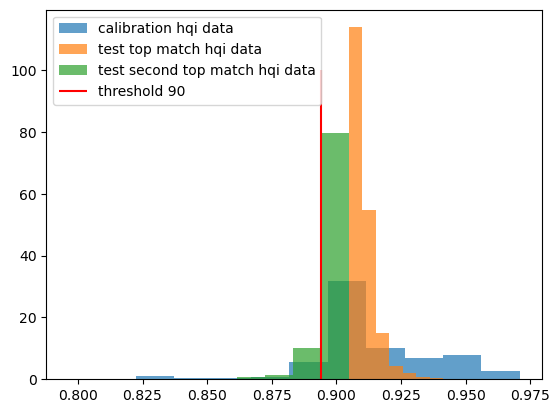

In [485]:
plt.hist(smx_cal[np.arange(label_cal_ir.shape[0]), label_cal_ir], density=True, label='calibration hqi data', alpha=.7)
plt.hist(np.max(smx_test, 1), density=True, label='test top match hqi data', alpha=.7)
plt.hist(np.sort(smx_test, 1)[:,-2], density=True, label='test second top match hqi data', alpha=.7)
#plt.vlines(0.8938658598510795,0, 100, color='red', label='threshold 90%')
#plt.vlines(0.9018570669179764,0, 100, color='red', label='threshold 75%')
plt.vlines(1-qhat,0, 100, color='red', label='threshold '+str(int(100*(1-alpha))))
plt.legend()

In [293]:
# Calculate HQI for calibration set
smx_cal = smx_log(X_train_raman, 
                  X_cal_raman, 
                  label_train_raman)

# Calculate HQI for test set
smx_test = smx_log(X_train_raman, 
                   X_test_raman, 
                   label_train_raman)

#smx_test_all = smx_nn_all(
#        X_train_raman, 
#        X_test_raman, 
#        label_train_raman
#)

#pred_slopp_df = [
#    np.array(label_table_raman.iloc[np.argmax(smx_test, 1),1]),
#    np.max(smx_test, 1),
#    np.array(reference_library_raman.iloc[np.argmax(smx_test_all, 0),0])
#]

# Set confidence level 1 - alpha
n = smx_cal.shape[0]
#for alpha in [alpha]:
prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal_raman, n, alpha, cond=0)

prediction_sets_n_raman = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n_raman])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())
print('HQI cutt off:', 1-qhat)

Sets with zero labels: 0
Sets with one label: 739
Sets with >1 labels: 3334
Mean set size: 4.710532776822981
Std set size: 2.716207827181222
HQI cutt off: 0.02905000690510917


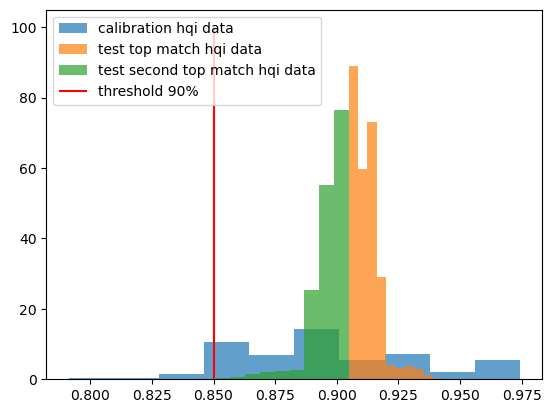

In [487]:
plt.hist(smx_cal[np.arange(label_cal_ir.shape[0]), label_cal_ir], density=True, label='calibration hqi data', alpha=.7)
plt.hist(np.max(smx_test, 1), density=True, label='test top match hqi data', alpha=.7)
plt.hist(np.sort(smx_test, 1)[:,-2], density=True, label='test second top match hqi data', alpha=.7)
plt.vlines(1-qhat,0, 100, color='red', label='threshold 90%')
plt.legend()

In [489]:
smx_all_IR = 1-np.power(smx_nn(X_train_ir, X_cal_ir, label_train_ir),1)
smx_all_Raman = 1-np.power(smx_nn(X_train_raman, X_cal_raman, label_train_raman),1)

smx_all_IR_test = 1-np.power(smx_nn(X_train_ir, X_test_ir, label_train_ir),1)
smx_all_Raman_test = 1-np.power(smx_nn(X_train_raman, X_test_raman, label_train_raman),1)


score_list = [smx_all_IR, smx_all_Raman]
score_list_test = [smx_all_IR_test, smx_all_Raman_test]

#alpha = .1
seed = 1
K = 2
quant_smx_list = []
rest_smx_list = []
cal_smx_list = []
val_smx_list = []
U_list = gen_u(K, seed=0)

for i in range(K):
    #quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed)
    quant_smx, cal_smx, quant_labels, cal_labels, idx_quant = split_cal_test(score_list[i], label_cal_ir, cal_prop=0.1, seed=seed)
    
    val_smx, val_labels = score_list_test[i], None
    
    #y_val = list(label_table.iloc[val_labels,1])
    
    #y_val_ir = np.array(notes_mix_std.loc[~idx_quant,:].loc[~idx,'polymer_ir'])
    #y_val_raman = np.array(notes_mix_std.loc[~idx_quant,:].loc[~idx,'polymer_raman'])
    
    quant_smx_list.append(quant_smx)
    #rest_smx_list.append(rest_smx)
    cal_smx_list.append(cal_smx)
    val_smx_list.append(val_smx)

n = cal_labels.shape[0]

prediction_sets = mvcp_2(quant_smx_list, 
                                             quant_labels,   
                                             cal_smx_list,   
                                             cal_labels,   
                                             val_smx_list,   
                                             alpha,     
                                             val_labels,                 
                                             U=U_list[0])

prediction_sets_n_mvcp = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n_mvcp])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Sets with zero labels: 9
Sets with one label: 198
Sets with >1 labels: 3860
Mean set size: 5.858372264568478
Std set size: 4.351147717318681


In [113]:
output = [prediction_sets_n[i][0] if i in single_label else 
              '--outlier--' if i in zero_label else 
              '--manual check!--' for i in range(label_test_ir.shape[0])]
output_df = pd.DataFrame({'id':test_set_ir['id'],
                          'prection_set_ir':prediction_sets_n,
                          'prection_set_raman':prediction_sets_n_raman,
                          'prection_set_mvcp':prediction_sets_n_mvcp,
                              #'output':output
                              })

output_df['polymer_flopp'] = pred_flopp_df[0]#np.array(pred_flopp_df[0])#['polymer_ref']
output_df['hqi_flopp'] = pred_flopp_df[1]#pred_flopp_df[1]#['hqi_ref']
output_df['id_top_match_flopp'] = pred_flopp_df[2]#np.array(flopp_df.iloc[np.array(pred_flopp_df[0].index),-1])

output_df['polymer_slopp'] = pred_slopp_df[0]#np.array(pred_slopp_df[0])#['polymer_ref']
output_df['hqi_slopp'] = pred_slopp_df[1]#pred_slopp_df[1]#['hqi_ref']
output_df['id_top_match_slopp'] = pred_slopp_df[2]#np.array(slopp_df.iloc[np.array(pred_slopp_df[0].index),-1])


output_df.to_csv(directory_name+'/CP_results_passive_paired.csv')

In [14]:
#output_df_p = pd.read_csv('CP_restuls.csv')
#del output_df_p['Unnamed: 0']
#output_df_p

#output_df_compare = pd.merge(output_df.iloc[:,[0,4,5,6,7,8,9]], output_df_p.iloc[:,[0,4,5,6,7,8,9]],on='id')
#output_df_compare

#(np.mean([len(x) for x in output_df['prection_set_ir']]), 
#np.mean([len(x) for x in output_df['prection_set_raman']]),
#np.mean([len(x) for x in output_df['prection_set_mvcp']]))

#(np.mean([x.count(',')+1 for x in output_df_p['prection_set_ir']]), 
#np.mean([x.count(',')+1 for x in output_df_p['prection_set_raman']]),
#np.mean([x.count(',')+1 for x in output_df_p['prection_set_mvcp']]))

# Unpaired Raman

In [337]:
(reference_library_raman, 
 calibration_set_raman, 
 test_set_raman, 
 label_table_raman) = gen_data_sets(slopp_df, 
                              rebecca_raman_df, 
                              passive_data_raman_unpaired_ram)

(X_train_raman, X_cal_raman, X_test_raman, 
 y_train_raman, y_cal_raman, y_test_raman, 
 label_train_raman, label_cal_raman, label_test_raman, 
 n_test_raman, wl_list_raman) = process_data(reference_library_raman,
                                 calibration_set_raman,
                                 test_set_raman)


(reference_library_ir, 
 calibration_set_ir, 
 test_set_ir, 
 label_table_ir) = gen_data_sets_ir(flopp_df, 
                              rebecca_ir_df, 
                              passive_data_ir_unpaired_ram)

(X_train_ir, X_cal_ir, X_test_ir, 
 y_train_ir, y_cal_ir, y_test_ir, 
 label_train_ir, label_cal_ir, label_test_ir, 
 n_test_ir, wl_list_ir) = process_data_ir(reference_library_ir,
                                 calibration_set_ir,
                                 test_set_ir)



        
#pred_slopp_df = corr_matching(np.array(slopp_df.iloc[:,:-4]), 
#                              slopp_df['polymer'], 
#                              np.array(test_set_raman.iloc[:,3:]), r_min=0)

#pred_flopp_df = corr_matching(np.array(flopp_df.iloc[:,:-4]), 
#                              flopp_df['polymer'], 
#                              np.array(test_set_ir.iloc[:,3:]), r_min=0)


In [347]:
(np.min(X_train_raman.mean(1)), np.max(X_train_raman.mean(1)),
np.min(X_train_raman.std(1)), np.max(X_train_raman.std(1)))

(-2.599012076584923e-15,
 4.1844728528331926e-15,
 0.9999999999999838,
 1.000000000000023)

In [349]:
(np.min(X_test_raman.mean(1)), np.max(X_test_raman.mean(1)),
np.min(X_test_raman.std(1)), np.max(X_test_raman.std(1)))

(-3.4079842043478627e-15,
 3.1464476982462854e-15,
 0.9999999999999852,
 1.000000000000016)

In [341]:
# Calculate HQI for calibration set
smx_cal = smx_nn(X_train_raman, 
                 X_cal_raman, 
                 label_train_raman)#, C=0.002)

# Calculate HQI for test set
smx_test = smx_nn(X_train_raman, 
                  X_test_raman, 
                  label_train_raman)#, C=0.002)

#smx_test_all = smx_nn_all(
#        X_train_raman, 
#        X_test_raman, 
#        label_train_raman
#)

#pred_slopp_df = [
#    np.array(label_table_raman.iloc[np.argmax(smx_test, 1),1]),
#    np.max(smx_test, 1),
#    np.array(reference_library_raman.iloc[np.argmax(smx_test_all, 0),0])
#]

# Set confidence level 1 - alpha
n = smx_cal.shape[0]
alpha = 0.1
#for alpha in [alpha]:
prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal_raman, n, alpha, cond=0)

prediction_sets_n_raman = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n_raman])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Sets with zero labels: 0
Sets with one label: 0
Sets with >1 labels: 1824
Mean set size: 13.956688596491228
Std set size: 0.5459070188258192


In [342]:
output_df = pd.DataFrame({'id':test_set_raman['id'],
                          'prection_set_size':prediction_sets.sum(1),
                          #'prection_set_raman':prediction_sets_n_raman,
                          #'prection_set_mvcp':prediction_sets_n_mvcp,
                              #'output':output
                              })

output_df['sort'] = 'other'
output_df.loc[[x in Passive_RamanOnly_Manual_LikelyMPs for x in output_df['id']],'sort'] = "LikelyMPs"
#output_df.loc[[x in FINAL_PTIR_Noise for x in output_df['id']],'sort'] = "Noise"
#output_df.loc[[x in FINAL_PTIR_NonMPs for x in output_df['id']],'sort'] = "NonMPs"

In [315]:
output_df.groupby(['sort']).mean()

,prection_set_size
sort,
LikelyMPs,13.391106
other,13.903907


In [343]:
output_df.groupby(['sort']).mean()

,prection_set_size
sort,
LikelyMPs,13.950969
other,13.961985


In [319]:
output_df.groupby(['sort']).mean()

,prection_set_size
sort,
LikelyMPs,1.481186
other,3.189018


In [340]:
output_df.groupby(['sort']).mean()

,prection_set_size
sort,
LikelyMPs,3.911060
other,4.487856


In [118]:
output = [prediction_sets_n[i][0] if i in single_label else 
              '--outlier--' if i in zero_label else 
              '--manual check!--' for i in range(label_test_ir.shape[0])]
output_df = pd.DataFrame({'id':test_set_ir['id'],
                          #'prection_set_ir':prediction_sets_n,
                          'prection_set_raman':prediction_sets_n_raman,
                          #'prection_set_mvcp':prediction_sets_n_mvcp,
                              #'output':output
                              })

#output_df['polymer_flopp'] = np.array(pred_flopp_df[0])#['polymer_ref']
#output_df['hqi_flopp'] = pred_flopp_df[1]#['hqi_ref']
#output_df['id_top_match_flopp'] = np.array(flopp_df.iloc[np.array(pred_flopp_df[0].index),-1])

output_df['polymer_slopp'] = pred_slopp_df[0]#np.array(pred_slopp_df[0])#['polymer_ref']
output_df['hqi_slopp'] = pred_slopp_df[1]#pred_slopp_df[1]#['hqi_ref']
output_df['id_top_match_slopp'] = pred_slopp_df[2]#np.array(slopp_df.iloc[np.array(pred_slopp_df[0].index),-1])


output_df.to_csv(directory_name+'/CP_results_passive_unpaired_raman.csv')

# Unpaired IR

In [255]:
(reference_library_raman, 
 calibration_set_raman, 
 test_set_raman, 
 label_table_raman) = gen_data_sets(slopp_df, 
                              rebecca_raman_df, 
                              passive_data_raman_unpaired_ir)

(X_train_raman, X_cal_raman, X_test_raman, 
 y_train_raman, y_cal_raman, y_test_raman, 
 label_train_raman, label_cal_raman, label_test_raman, 
 n_test_raman, wl_list_raman) = process_data(reference_library_raman,
                                 calibration_set_raman,
                                 test_set_raman)


(reference_library_ir, 
 calibration_set_ir, 
 test_set_ir, 
 label_table_ir) = gen_data_sets_ir(flopp_df, 
                              rebecca_ir_df, 
                              passive_data_ir_unpaired_ir)

(X_train_ir, X_cal_ir, X_test_ir, 
 y_train_ir, y_cal_ir, y_test_ir, 
 label_train_ir, label_cal_ir, label_test_ir, 
 n_test_ir, wl_list_ir) = process_data_ir(reference_library_ir,
                                 calibration_set_ir,
                                 test_set_ir)



        
pred_slopp_df = corr_matching(np.array(slopp_df.iloc[:,:-4]), 
                              slopp_df['polymer'], 
                              np.array(test_set_raman.iloc[:,3:]), r_min=0)

pred_flopp_df = corr_matching(np.array(flopp_df.iloc[:,:-4]), 
                              flopp_df['polymer'], 
                              np.array(test_set_ir.iloc[:,3:]), r_min=0)


In [256]:
# Calculate HQI for calibration set
smx_cal = smx_nn(X_train_ir, X_cal_ir, label_train_ir)

# Calculate HQI for test set
smx_test = smx_nn(X_train_ir, X_test_ir, label_train_ir)

#smx_test_all = smx_nn_all(
#        X_train_ir, 
#        X_test_ir, 
#        label_train_ir
#)

#pred_flopp_df = [
#    np.array(label_table_ir.iloc[np.argmax(smx_test, 1),1]),
#    np.max(smx_test, 1),
#    np.array(reference_library_ir.iloc[np.argmax(smx_test_all, 0),0])
#]

# Set confidence level 1 - alpha
n = smx_cal.shape[0]
alpha = 0.1
#for alpha in [alpha]:
prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal_ir, n, alpha, cond=0)

prediction_sets_n = [list(label_table_ir.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Sets with zero labels: 0
Sets with one label: 765
Sets with >1 labels: 1331
Mean set size: 2.5229007633587788
Std set size: 2.078940749277634


In [257]:
output_df = pd.DataFrame(prediction_sets*1)
output_df.columns = list(label_table_ir['polymer'])
output_df['id'] = test_set_ir['id']
output_df['sort'] = 'other'
output_df.loc[[x in FINAL_PTIR_LikelyMPs for x in output_df['id']],'sort'] = "LikelyMPs"
output_df.loc[[x in FINAL_PTIR_Noise for x in output_df['id']],'sort'] = "Noise"
output_df.loc[[x in FINAL_PTIR_NonMPs for x in output_df['id']],'sort'] = "NonMPs"

res_by_poly = output_df.groupby(['sort']).mean().T#.to_dict()
res_by_poly

sort,LikelyMPs,Noise,NonMPs,other
Acrylic,0.025696,0.165854,0.003759,0.018998
Acrylonitrile Butadiene Styrene,0.066381,0.346341,0.018797,0.066494
Cellulose Acetate,0.002141,0.165854,0.015038,0.024180
Polyamide,0.203426,0.200000,0.052632,0.077720
Polycarbonate,0.002141,0.131707,0.011278,0.013817
Polyethylene,0.164882,0.414634,0.026316,0.084629
Polyethylene Terephthalate,0.081370,0.243902,0.142857,0.173575
Polyethylene Vinyl Acetate,0.064240,0.273171,0.015038,0.030225
Polymethyl Methacrylate,0.032120,0.151220,0.011278,0.023316
Polypropylene,0.396146,0.624390,0.293233,0.341105


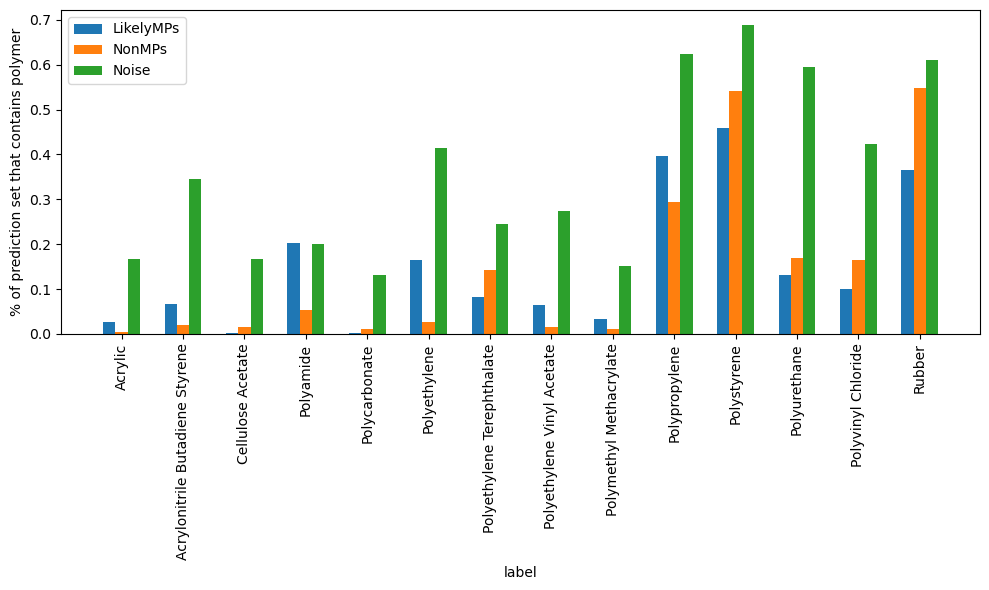

In [258]:
x = range(14)
width = 0.2
    
plt.figure(figsize=(10,6))
plt.bar([xi - width for xi in x], 
        res_by_poly["LikelyMPs"], 
        width=width, 
        label="LikelyMPs")

plt.bar([xi for xi in x], 
        res_by_poly["NonMPs"], 
        width=width, 
        label="NonMPs")

plt.bar([xi + width for xi in x], 
        res_by_poly["Noise"], 
        width=width, 
        label="Noise")



plt.xticks(x, label_table_ir["polymer"], rotation=90)
plt.xlabel("label")
plt.ylabel("% of prediction set that contains polymer")
plt.legend()
plt.tight_layout()
plt.show()

In [259]:
output_df = pd.DataFrame({'id':test_set_ir['id'],
                          'prection_set_size':prediction_sets.sum(1),
                          #'prection_set_raman':prediction_sets_n_raman,
                          #'prection_set_mvcp':prediction_sets_n_mvcp,
                              #'output':output
                              })

output_df['sort'] = 'other'
output_df.loc[[x in FINAL_PTIR_LikelyMPs for x in output_df['id']],'sort'] = "LikelyMPs"
output_df.loc[[x in FINAL_PTIR_Noise for x in output_df['id']],'sort'] = "Noise"
output_df.loc[[x in FINAL_PTIR_NonMPs for x in output_df['id']],'sort'] = "NonMPs"

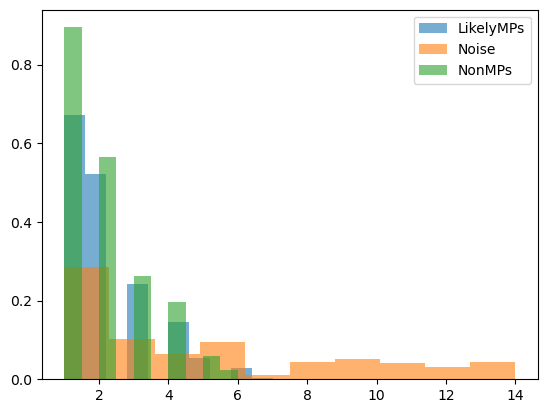

In [268]:
plt.hist(output_df.query('sort == "LikelyMPs"')['prection_set_size'], density=True, alpha=.6, label='LikelyMPs')
plt.hist(output_df.query('sort == "Noise"')['prection_set_size'], density=True, alpha=.6, label='Noise')
plt.hist(output_df.query('sort == "NonMPs"')['prection_set_size'], density=True, alpha=.6, label='NonMPs')
plt.legend()

In [200]:
output_df.groupby(['sort']).mean()

,prection_set_size
sort,
LikelyMPs,2.094218
Noise,5.034146
NonMPs,2.015038
other,2.367876


In [237]:
# Calculate HQI for calibration set
smx_cal = smx_log(X_train_ir, X_cal_ir, label_train_ir, C=0.002)

# Calculate HQI for test set
smx_test = smx_log(X_train_ir, X_test_ir, label_train_ir, C=0.002)

#smx_test_all = smx_nn_all(
#        X_train_ir, 
#        X_test_ir, 
#        label_train_ir
#)

#pred_flopp_df = [
#    np.array(label_table_ir.iloc[np.argmax(smx_test, 1),1]),
#    np.max(smx_test, 1),
#    np.array(reference_library_ir.iloc[np.argmax(smx_test_all, 0),0])
#]

# Set confidence level 1 - alpha
n = smx_cal.shape[0]
alpha = 0.1
#for alpha in [alpha]:
prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal_ir, n, alpha, cond=0)

prediction_sets_n = [list(label_table_ir.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Sets with zero labels: 0
Sets with one label: 1
Sets with >1 labels: 2095
Mean set size: 6.166984732824427
Std set size: 1.5527547767479186


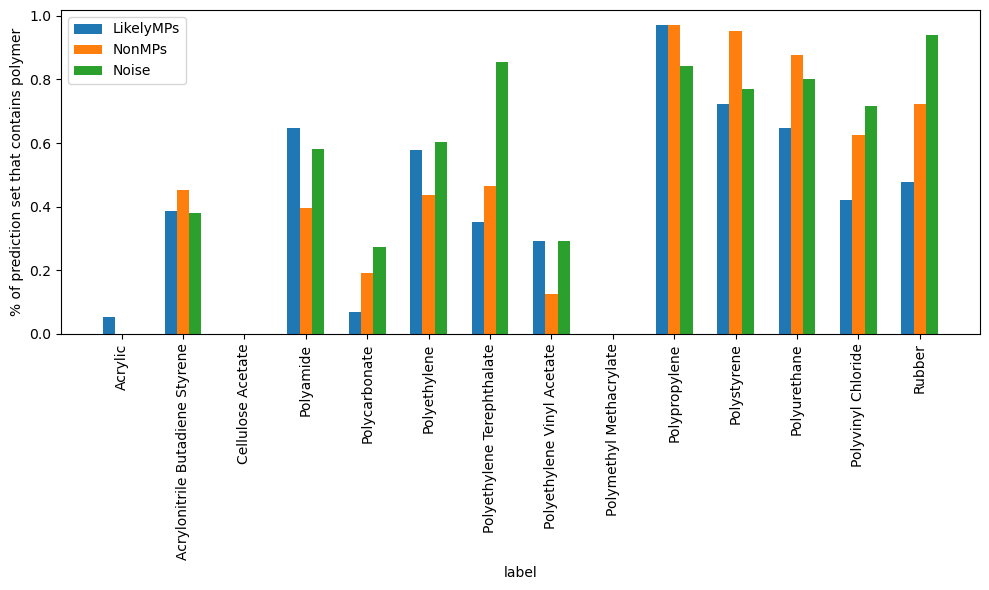

In [238]:
output_df = pd.DataFrame(prediction_sets*1)
output_df.columns = list(label_table_ir['polymer'])
output_df['id'] = test_set_ir['id']
output_df['sort'] = 'other'
output_df.loc[[x in FINAL_PTIR_LikelyMPs for x in output_df['id']],'sort'] = "LikelyMPs"
output_df.loc[[x in FINAL_PTIR_Noise for x in output_df['id']],'sort'] = "Noise"
output_df.loc[[x in FINAL_PTIR_NonMPs for x in output_df['id']],'sort'] = "NonMPs"

res_by_poly = output_df.groupby(['sort']).mean().T#.to_dict()

x = range(14)
width = 0.2
    
plt.figure(figsize=(10,6))
plt.bar([xi - width for xi in x], 
        res_by_poly["LikelyMPs"], 
        width=width, 
        label="LikelyMPs")

plt.bar([xi for xi in x], 
        res_by_poly["NonMPs"], 
        width=width, 
        label="NonMPs")

plt.bar([xi + width for xi in x], 
        res_by_poly["Noise"], 
        width=width, 
        label="Noise")



plt.xticks(x, label_table_ir["polymer"], rotation=90)
plt.xlabel("label")
plt.ylabel("% of prediction set that contains polymer")
plt.legend()
plt.tight_layout()
plt.show()

In [239]:
output_df = pd.DataFrame({'id':test_set_ir['id'],
                          'prection_set_size':prediction_sets.sum(1),
                          #'prection_set_raman':prediction_sets_n_raman,
                          #'prection_set_mvcp':prediction_sets_n_mvcp,
                              #'output':output
                              })

output_df['sort'] = 'other'
output_df.loc[[x in FINAL_PTIR_LikelyMPs for x in output_df['id']],'sort'] = "LikelyMPs"
output_df.loc[[x in FINAL_PTIR_Noise for x in output_df['id']],'sort'] = "Noise"
output_df.loc[[x in FINAL_PTIR_NonMPs for x in output_df['id']],'sort'] = "NonMPs"

output_df.groupby(['sort']).mean()

,prection_set_size
sort,
LikelyMPs,5.618844
Noise,7.058537
NonMPs,6.206767
other,6.221071
